# LangGraph Workflow

In [1]:
import random
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_core.messages import HumanMessage, SystemMessage
from langchain_openai import ChatOpenAI
from IPython.display import Image, display

In [2]:
class State(TypedDict):
    input: int
    output: int

In [3]:
random.randint(1, 10)

1

In [4]:
def node_a(state: State) -> State:
    input_value = state["input"]
    offset = random.randint(1, 10)
    output = input_value + offset
    print(f"NODE A:\n ->input:{input_value}\n ->offset:{offset}\n ->output:{output}\n ")
    return State(output=output)

In [5]:
def node_b(state: State):
    input_value = state["output"]
    offset = random.randint(1, 10)
    output = input_value + offset
    print(f"NODE B:\n ->input:{input_value}\n ->offset:{offset}\n ->output:{output}\n ")
    return {"output": output}

In [6]:
workflow = StateGraph(state_schema=State)

In [7]:
workflow.add_node(node_a)
workflow.add_node(node_b)

In [8]:
workflow.add_edge(START, "node_a")
workflow.add_edge("node_a", "node_b")
workflow.add_edge("node_b", END)

In [9]:
graph = workflow.compile()

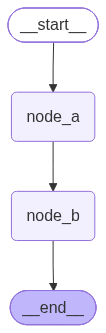

In [10]:
display(Image(graph.get_graph().draw_mermaid_png()))

In [11]:
graph.invoke(
    input={
        "input": 15,
    },
)

NODE A:
 ->input:15
 ->offset:6
 ->output:21
 
NODE B:
 ->input:21
 ->offset:1
 ->output:22
 


{'input': 15, 'output': 22}

In [12]:
from dotenv import load_dotenv

load_dotenv()

True

In [13]:
model = "gpt-5.6-sol"

In [14]:
llm = ChatOpenAI(
    model=model,
    temperature=0.0,
    max_tokens=500,
    timeout=500,
    reasoning_effort="low",
    max_retries=2,
)

In [15]:
class State(TypedDict):
    question: str
    response: str

In [16]:
def model(state: State):
    question = state["question"]
    response = llm.invoke(
        [SystemMessage("You're a React.js specialist"), HumanMessage(question)]
    )

    return {"response": response.content}

In [17]:
workflow = StateGraph(State)

In [18]:
workflow.add_node("model", model)

In [19]:
workflow.add_edge(START, "model")
workflow.add_edge("model", END)

In [20]:
graph = workflow.compile()

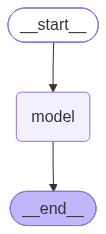

In [21]:
display(Image(graph.get_graph().draw_mermaid_png()))

In [22]:
result = graph.invoke(
    input={"question": "What's the useOptimistic hook in React?"},
)

In [23]:
result

{'question': "What's the useOptimistic hook in React?",
 'response': [{'id': 'rs_0292d99bb2891347006ab3e77a689087d2aa2f454913e050c3',
   'summary': [],
   'type': 'reasoning',
   'content': [],
   'encrypted_content': 'gAAAAABqs-eDH38ueXqRBWOvMPzSCeQcRvDm4SE-5coV9bsCZKCWy1F0iYNGxZ4jRVmkvJCqD8xo7Ne1EJSQf8vb3YiaGVybBQGa8vv_NSfvMwVCIdJxTY4L03r_jsixbNQz-kpTwXZzSm6ole84EM80zL9754OuTg70dIBJAyS1YllbkS_TCphDVWo29D0FN_86QKu8nINqdQ5HJhmw6dZL8pVbbTjk2Bfptt35zeQkKbEujXBfhaYwzqH3Q8Ht-w6W4gC8cnpMAC2L5qXp5ycgramPAg6N8cSOnR_xCxhA_3NBmLzX7KBZvYD43fmtsTwEJt-MvJPDGmBG2UUw-nFUZe-2V_ZBBG7gxh7REChO9V8hi1Ty9rbuz_kHOBnFVGiweESd0SVZRKJAJuLcMifZnVZ189TKFK4nOWK5taT_BgYI4Sz5ZvVvXdfNrZk16fq6oFX6wseL9_xW5yluHx8ELA4_gCmH8c_tzZv6pBxIsyefeCLhVl0ZX9d_2Rxb282G8D8dzv9f_-57B9MkfQmw4_cWPtapUVIPg05Uuq9sRhiWjxes1w-xrcuz_mEwqAsSOPUl_J9eBXazZC6casNDt2gekdY-ke5MvvTDzEX0K7UKUWHlrTXFVpct25p7f6J9_le2kXXHq5vrb6bZbB31a27pui8f1inV-S5bgdM0Ejh6nOgrPswcUTPm3CjYQpnU_xWlUaqZWYNi9LG57AzS7zhOoG5fbEUmuchaYtHLoPvtNf-TPcFA49ONB90ye_iPMefHQcxUw

In [26]:
result["response"]

[{'id': 'rs_0292d99bb2891347006ab3e77a689087d2aa2f454913e050c3',
  'summary': [],
  'type': 'reasoning',
  'content': [],
  'encrypted_content': 'gAAAAABqs-eDH38ueXqRBWOvMPzSCeQcRvDm4SE-5coV9bsCZKCWy1F0iYNGxZ4jRVmkvJCqD8xo7Ne1EJSQf8vb3YiaGVybBQGa8vv_NSfvMwVCIdJxTY4L03r_jsixbNQz-kpTwXZzSm6ole84EM80zL9754OuTg70dIBJAyS1YllbkS_TCphDVWo29D0FN_86QKu8nINqdQ5HJhmw6dZL8pVbbTjk2Bfptt35zeQkKbEujXBfhaYwzqH3Q8Ht-w6W4gC8cnpMAC2L5qXp5ycgramPAg6N8cSOnR_xCxhA_3NBmLzX7KBZvYD43fmtsTwEJt-MvJPDGmBG2UUw-nFUZe-2V_ZBBG7gxh7REChO9V8hi1Ty9rbuz_kHOBnFVGiweESd0SVZRKJAJuLcMifZnVZ189TKFK4nOWK5taT_BgYI4Sz5ZvVvXdfNrZk16fq6oFX6wseL9_xW5yluHx8ELA4_gCmH8c_tzZv6pBxIsyefeCLhVl0ZX9d_2Rxb282G8D8dzv9f_-57B9MkfQmw4_cWPtapUVIPg05Uuq9sRhiWjxes1w-xrcuz_mEwqAsSOPUl_J9eBXazZC6casNDt2gekdY-ke5MvvTDzEX0K7UKUWHlrTXFVpct25p7f6J9_le2kXXHq5vrb6bZbB31a27pui8f1inV-S5bgdM0Ejh6nOgrPswcUTPm3CjYQpnU_xWlUaqZWYNi9LG57AzS7zhOoG5fbEUmuchaYtHLoPvtNf-TPcFA49ONB90ye_iPMefHQcxUwD_aveISGNW5zI3nkyIqrC2bSVnk2Q5FDLaBoYllQmX3zYtZZdUv9-Nsm-YcImFsDjIBWLlJlC

In [31]:
result["response"][-1]["text"]

'`useOptimistic` is a React 19 Hook for **optimistic UI updates**—showing the expected result immediately while an asynchronous operation is still running.\n\n```jsx\nconst [optimisticState, addOptimisticUpdate] = useOptimistic(\n  actualState,\n  updateFn\n);\n```\n\n### Example\n\n```jsx\nimport { useOptimistic } from "react";\n\nfunction TodoList({ todos, saveTodo }) {\n  const [optimisticTodos, addOptimisticTodo] = useOptimistic(\n    todos,\n    (currentTodos, newTodo) => [\n      ...currentTodos,\n      { ...newTodo, pending: true },\n    ]\n  );\n\n  async function addTodo(formData) {\n    const todo = {\n      id: crypto.randomUUID(),\n      text: formData.get("text"),\n    };\n\n    addOptimisticTodo(todo); // Appears immediately\n'